# 04 · Human Activity Recognition — Clustering Without Labels

**Question.** Using smartphone sensor data alone, without the activity labels, can different physical activities be
told apart?

**Data.** UCI Human Activity Recognition dataset: accelerometer and gyroscope readings from a phone worn on the
waist (30 volunteers, 6 activities). 7,352 observations with **561 features**.

**Approach.** Data profiling → variance threshold (remove at most 10% of features) → standardisation → PCA →
choosing *k* with the elbow method and silhouette score → K-means → checking the clusters against the true labels
(ARI, NMI, contingency tables).

**Result.**

* PCA compresses 504 features into **56 components** that keep 90% of the variance — a 9× reduction.
* With *k* = 2 the clusters separate *moving* from *static* activities with only **17 errors in 7,352** observations.
* With *k* = 6, lying down is recognised well, while sitting and standing are indistinguishable — and the notebook
  explains why from the physics of the sensor.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             normalized_mutual_info_score)

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

## 1. Loading the data

The file is whitespace-separated and has no header, so the features are numbered automatically `0…560`.

In [2]:
X = pd.read_csv("../data/X_train.txt", sep=r"\s+", header=None)

print("Feature matrix shape:", X.shape)
X.iloc[:5, :6]

Feature matrix shape: (7352, 561)


,0,1,2,3,4,5
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482


## 2. Profiling the data

Three questions first: how many features, are there missing values, and do the features differ in scale.

In [3]:
print(f"Observations:        {X.shape[0]}")
print(f"Features:            {X.shape[1]}")
print(f"Missing values:      {int(X.isna().sum().sum())}")
print(f"Duplicate rows:      {int(X.duplicated().sum())}")
print(f"Data types:          {sorted({str(t) for t in X.dtypes})}")
print(f"Global minimum:      {X.min().min():.3f}")
print(f"Global maximum:      {X.max().max():.3f}")

Observations:        7352
Features:            561
Missing values:      0


Duplicate rows:      0
Data types:          ['float64']
Global minimum:      -1.000
Global maximum:      1.000


In [4]:
stats = X.describe().T[["min", "max", "mean", "std"]]
stats["range"] = stats["max"] - stats["min"]

print("Summary across the 561 features (the distribution of each statistic):")
display(stats.describe().round(3))

print(f"Range (max-min):     from {stats['range'].min():.3f} to {stats['range'].max():.3f}")
print(f"Standard deviation:  from {stats['std'].min():.4f} to {stats['std'].max():.4f} "
      f"({stats['std'].max() / stats['std'].min():.1f}x difference)")

Summary across the 561 features (the distribution of each statistic):


,min,max,mean,std,range
count,561.000,561.000,561.000,561.000,561.000
mean,-0.990,0.978,-0.508,0.284,1.969
std,0.050,0.069,0.428,0.137,0.085
min,-1.000,0.465,-0.984,0.041,1.462
25%,-1.000,1.000,-0.868,0.192,1.999
50%,-1.000,1.000,-0.659,0.265,2.000
75%,-1.000,1.000,-0.108,0.362,2.000
max,-0.494,1.000,0.830,0.752,2.000


Range (max-min):     from 1.462 to 2.000
Standard deviation:  from 0.0408 to 0.7517 (18.4x difference)


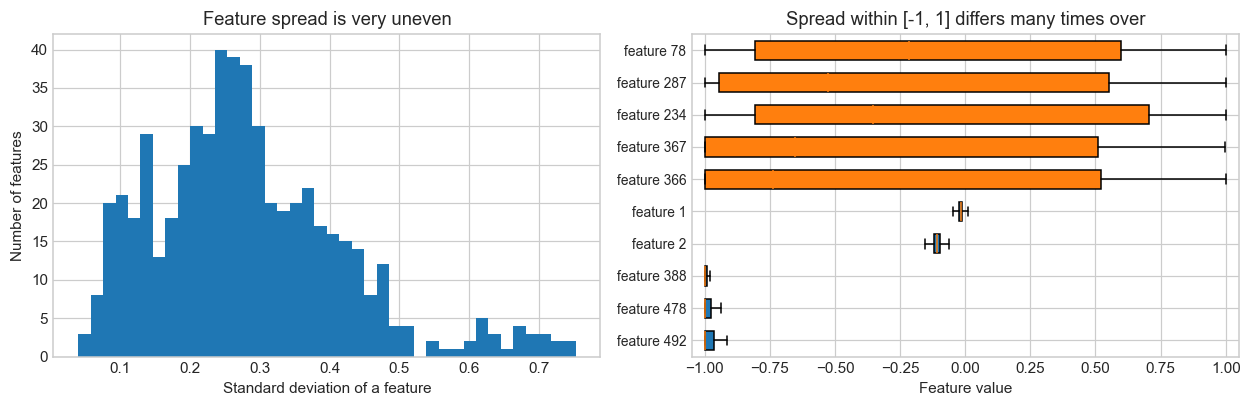

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

axes[0].hist(stats["std"], bins=40, color="C0")
axes[0].set_title("Feature spread is very uneven")
axes[0].set_xlabel("Standard deviation of a feature")
axes[0].set_ylabel("Number of features")

# the 5 narrowest and the 5 widest features: all within [-1, 1], but with very different spread
picked = list(stats["std"].nsmallest(5).index[::-1]) + list(stats["std"].nlargest(5).index)
box = axes[1].boxplot([X[c] for c in picked], vert=False, widths=0.6,
                      patch_artist=True, showfliers=False)
for i, patch in enumerate(box["boxes"]):
    patch.set_facecolor("C0" if i < 5 else "C1")

axes[1].set_yticks(range(1, 11), [f"feature {c}" for c in picked], fontsize=9)
axes[1].set_title("Spread within [-1, 1] differs many times over")
axes[1].set_xlabel("Feature value")
axes[1].set_xlim(-1.05, 1.05)

fig.tight_layout()
plt.show()

**What the data looks like:**

* 7,352 observations and **561 features** — statistics (mean, variance, energy, correlations, Fourier spectrum
  components) computed over windows of the accelerometer and gyroscope signals.
* **No missing values at all**, no duplicate rows, every feature is a float.
* **Scale.** The dataset authors already normalised every feature to `[-1, 1]`, so there is no "kilometres versus
  grams" problem. But the actual variability inside that interval differs almost **18-fold** (σ from 0.04 to 0.75).
  That matters for PCA: it maximises explained *variance*, so without standardisation the first components would be
  dominated by the widest-spread features. `StandardScaler` therefore comes before PCA.

## 3. Dimensionality reduction

### 3.1. Variance threshold

A feature that barely changes between observations cannot help separate activities, so it can go. The constraint is
to remove **no more than 10%** of the features, so the threshold is not picked arbitrarily: it is the 10th percentile of
the feature variances, which removes about 10% of the least informative columns.

In [6]:
variances = X.var()
threshold = variances.quantile(0.10)

selector = VarianceThreshold(threshold=threshold).fit(X)
mask = selector.get_support()
X_var = X.loc[:, mask]

dropped = int((~mask).sum())
print(f"Variance threshold:  {threshold:.5f}")
print(f"Features removed:    {dropped} ({dropped / X.shape[1]:.1%})")
print(f"Features left:       {X_var.shape[1]}")
print("\nExamples of removed features (index and variance):")
for c in X.columns[~mask][:5]:
    print(f"  feature {c:>3}: {variances[c]:.5f}")

Variance threshold:  0.01452
Features removed:    57 (10.2%)
Features left:       504

Examples of removed features (index and variance):
  feature   0: 0.00494
  feature   1: 0.00167
  feature   2: 0.00321
  feature  43: 0.00608
  feature  44: 0.00837


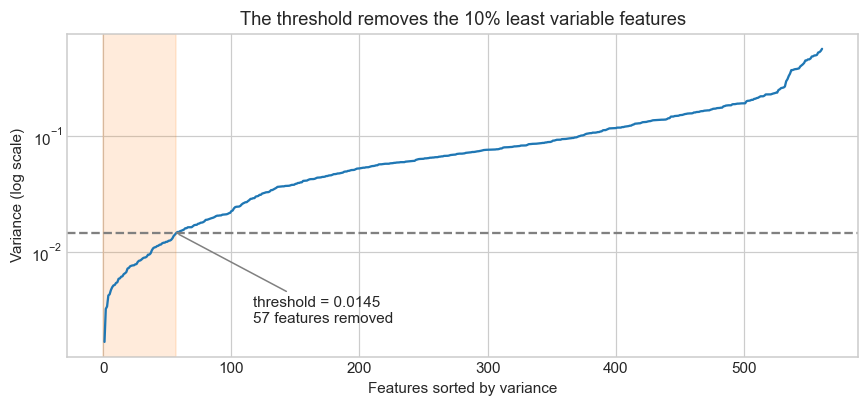

In [7]:
sorted_var = variances.sort_values().to_numpy()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(np.arange(1, len(sorted_var) + 1), sorted_var, color="C0")
ax.axhline(threshold, color="gray", linestyle="--")
ax.axvspan(0, dropped, color="C1", alpha=0.15)
ax.set_yscale("log")
ax.set_title("The threshold removes the 10% least variable features")
ax.set_xlabel("Features sorted by variance")
ax.set_ylabel("Variance (log scale)")
ax.annotate(f"threshold = {threshold:.4f}\n{dropped} features removed",
            xy=(dropped, threshold), xytext=(dropped + 60, threshold / 6),
            arrowprops=dict(arrowstyle="-", color="gray"))
fig.tight_layout()
plt.show()

### 3.2. Principal component analysis

Standardise first, then fit PCA.

In [8]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_var)
print("After standardisation: mean =", round(float(X_scaled.mean()), 10),
      ", std =", round(float(X_scaled.std()), 6))

pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumvar = np.cumsum(explained)

n90 = int(np.searchsorted(cumvar, 0.90) + 1)

print("\nComponents needed for a given share of explained variance:")
for level in (0.80, 0.90, 0.95, 0.99):
    print(f"  {level:.0%} -> {int(np.searchsorted(cumvar, level) + 1):3d} components")

print(f"\nThe first component alone explains {explained[0]:.1%} of the variance,")
print(f"the first two together {cumvar[1]:.1%}.")

After standardisation: mean = 0.0 , std = 1.0

Components needed for a given share of explained variance:
  80% ->  22 components
  90% ->  56 components
  95% ->  91 components
  99% -> 159 components

The first component alone explains 53.0% of the variance,
the first two together 59.5%.


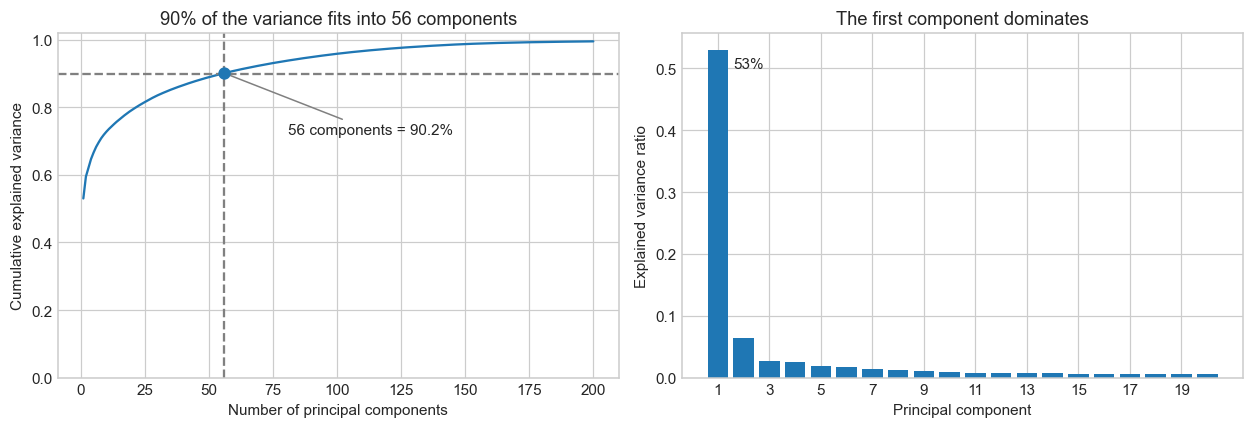

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

# left: cumulative explained variance
n_show = 200
axes[0].plot(np.arange(1, n_show + 1), cumvar[:n_show], color="C0")
axes[0].axhline(0.90, color="gray", linestyle="--")
axes[0].axvline(n90, color="gray", linestyle="--")
axes[0].scatter([n90], [cumvar[n90 - 1]], s=50, color="C0", zorder=5)
axes[0].annotate(f"{n90} components = {cumvar[n90 - 1]:.1%}",
                 xy=(n90, cumvar[n90 - 1]), xytext=(n90 + 25, 0.72),
                 arrowprops=dict(arrowstyle="-", color="gray"))
axes[0].set_title(f"90% of the variance fits into {n90} components")
axes[0].set_xlabel("Number of principal components")
axes[0].set_ylabel("Cumulative explained variance")
axes[0].set_ylim(0, 1.02)

# right: contribution of individual components
axes[1].bar(np.arange(1, 21), explained[:20], color="C0")
axes[1].set_title("The first component dominates")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Explained variance ratio")
axes[1].set_xticks(range(1, 21, 2))
axes[1].annotate(f"{explained[0]:.0%}", xy=(1.6, explained[0] - 0.03))

fig.tight_layout()
plt.show()

**The minimum number of components is 56**, explaining 90.2% of the original variance. That is a **9× compression**,
504 features → 56 components, with almost no information lost. Such redundancy is expected: the 561 original features
are many re-computations over the same three accelerometer and gyroscope axes, so they are strongly correlated.

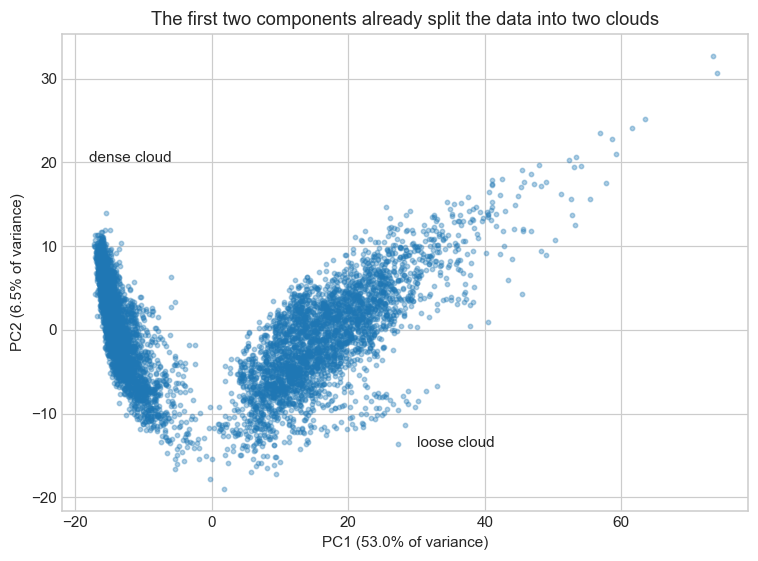

In [10]:
X_pca_full = pca_full.transform(X_scaled)
pc1, pc2 = X_pca_full[:, 0], X_pca_full[:, 1]

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.scatter(pc1, pc2, s=8, alpha=0.35, color="C0")
ax.set_title("The first two components already split the data into two clouds")
ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
ax.text(-18, 20, "dense cloud")
ax.text(30, -14, "loose cloud")
fig.tight_layout()
plt.show()

Even without labels the main structure is visible: the observations fall into **two well-separated clouds** along the
first component, a dense one on the left and a noticeably looser one on the right. The new components carry real
structure, not noise.

## 4. Choosing the number of clusters

Clustering runs in the space of the 56 principal components: no multicollinearity, less noise and faster K-means.
The elbow method uses inertia (the sum of squared distances to centroids); the silhouette score is computed as a
cross-check of how well the clusters separate.

In [11]:
X_pca = X_pca_full[:, :n90]

k_range = range(1, 11)
inertia, silhouette = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    inertia.append(km.inertia_)
    if k > 1:
        silhouette.append(silhouette_score(X_pca, km.labels_,
                                           sample_size=3000, random_state=RANDOM_STATE))

drop = [100 * (inertia[i - 1] - inertia[i]) / inertia[i - 1] for i in range(1, len(inertia))]
print("How much inertia falls with each extra cluster:")
for i, d in enumerate(drop, start=2):
    print(f"  {i - 1} -> {i} clusters: -{d:.1f} %")

How much inertia falls with each extra cluster:
  1 -> 2 clusters: -51.3 %
  2 -> 3 clusters: -12.9 %
  3 -> 4 clusters: -7.1 %
  4 -> 5 clusters: -5.8 %
  5 -> 6 clusters: -4.2 %
  6 -> 7 clusters: -3.2 %
  7 -> 8 clusters: -3.3 %
  8 -> 9 clusters: -2.7 %
  9 -> 10 clusters: -2.6 %


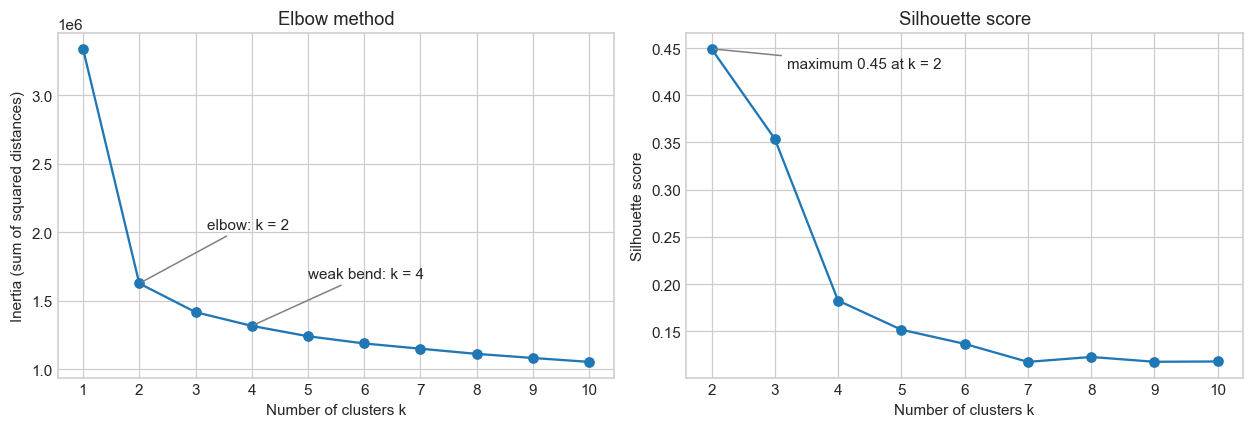

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))

axes[0].plot(list(k_range), inertia, color="C0", marker="o")
axes[0].annotate("elbow: k = 2", xy=(2, inertia[1]), xytext=(3.2, inertia[1] + 4e5),
                 arrowprops=dict(arrowstyle="-", color="gray"))
axes[0].annotate("weak bend: k = 4", xy=(4, inertia[3]), xytext=(5.0, inertia[3] + 3.5e5),
                 arrowprops=dict(arrowstyle="-", color="gray"))
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters k")
axes[0].set_ylabel("Inertia (sum of squared distances)")
axes[0].set_xticks(list(k_range))

axes[1].plot(list(k_range)[1:], silhouette, color="C0", marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters k")
axes[1].set_ylabel("Silhouette score")
axes[1].set_xticks(list(k_range)[1:])
axes[1].annotate(f"maximum {max(silhouette):.2f} at k = 2",
                 xy=(2, silhouette[0]), xytext=(3.2, silhouette[0] - 0.02),
                 arrowprops=dict(arrowstyle="-", color="gray"))

fig.tight_layout()
plt.show()

### Which k to choose

The formal criteria agree: inertia drops by **51%** going from 1 to 2 clusters, after which each drop is at least three
times smaller (13%, 7%, 6%, …), and the silhouette score peaks at k = 2 (0.45) and declines steadily from there.
**Geometrically the data contains exactly two dense, well-separated groups** — the two clouds seen on the PC1/PC2 plot.
A second, much weaker bend appears at k = 4.

The task has a substantive side, though: there are six real activities, and two groups do not answer the question.
So both options are examined:

* **k = 2** — the statistically optimal split;
* **k = 6** — the number of real activities, to see how much of them K-means can recover without labels.

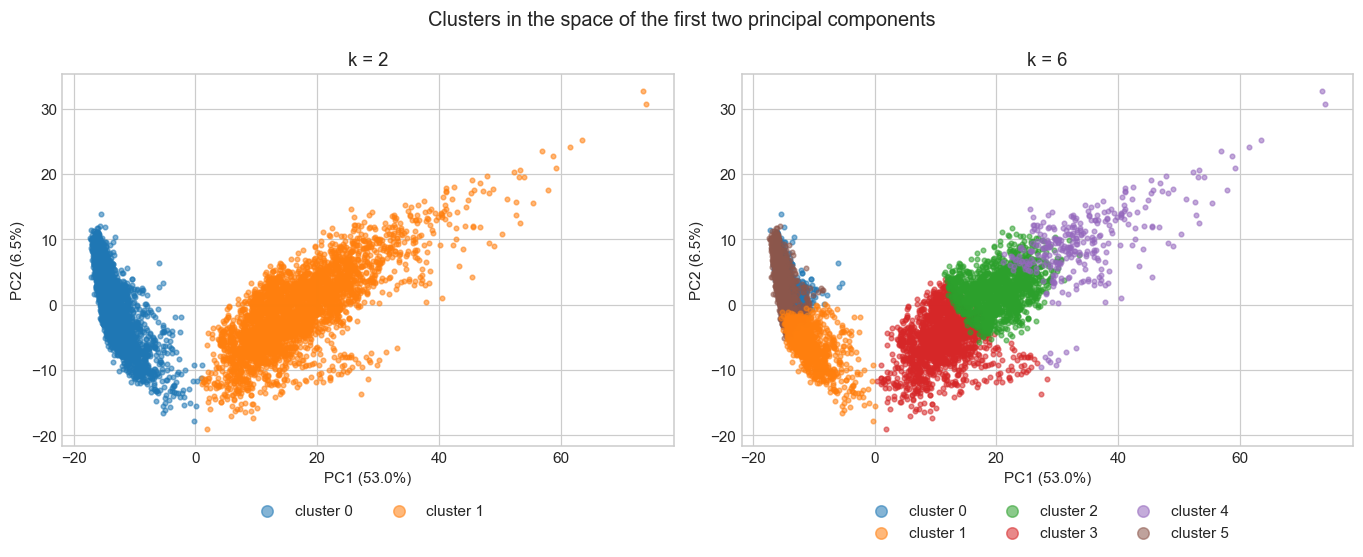

In [13]:
labels_k = {}
for k in (2, 4, 6):
    labels_k[k] = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))

for ax, k in zip(axes, (2, 6)):
    # draw large clusters first so the small ones stay visible on top
    for c in np.argsort(-np.bincount(labels_k[k])):
        m = labels_k[k] == c
        ax.scatter(pc1[m], pc2[m], s=9, alpha=0.55, color=f"C{c}", label=f"cluster {c}")
    ax.set_title(f"k = {k}")
    ax.set_xlabel(f"PC1 ({explained[0]:.1%})")
    ax.set_ylabel(f"PC2 ({explained[1]:.1%})")
    h, lb = ax.get_legend_handles_labels()
    o = np.argsort(lb)
    ax.legend([h[i] for i in o], [lb[i] for i in o], loc="upper center", ncol=3,
              markerscale=2.5, bbox_to_anchor=(0.5, -0.12))

fig.suptitle("Clusters in the space of the first two principal components", fontsize=13)
fig.tight_layout()
plt.show()

With k = 2 the boundary runs exactly through the gap between the clouds. With k = 6 each cloud splits into three
parts, and inside the left cloud the boundaries look arbitrary — the clusters sit right next to each other.

## 5. Evaluating the clusters against the true labels

Clustering does not have to guess the class *numbers*; what matters is whether the grouping matches. So the check
uses contingency tables and partition-agreement metrics: ARI and NMI (0 means chance-level agreement, 1 a perfect match).

In [14]:
y = pd.read_csv("../data/y_train.txt", header=None, names=["activity_id"])["activity_id"]
activity_labels = (pd.read_csv("../data/activity_labels.txt", sep=r"\s+", header=None,
                               names=["activity_id", "activity"])
                     .set_index("activity_id")["activity"])
y_named = y.map(activity_labels)

print("Label codes:")
print(activity_labels.to_string())
print("\nObservations per activity:")
print(y_named.value_counts().to_string())

Label codes:
activity_id
1               WALKING
2      WALKING_UPSTAIRS
3    WALKING_DOWNSTAIRS
4               SITTING
5              STANDING
6                LAYING

Observations per activity:
activity_id
LAYING                1407
STANDING              1374
SITTING               1286
WALKING               1226
WALKING_UPSTAIRS      1073
WALKING_DOWNSTAIRS     986


In [15]:
print("Agreement between clusters and real activities:\n")
print(f"{'k':>3} | {'ARI':>6} | {'NMI':>6}")
print("-" * 21)
for k in (2, 4, 6):
    print(f"{k:>3} | {adjusted_rand_score(y, labels_k[k]):>6.3f} | "
          f"{normalized_mutual_info_score(y, labels_k[k]):>6.3f}")

Agreement between clusters and real activities:

  k |    ARI |    NMI
---------------------
  2 |  0.329 |  0.545
  4 |  0.289 |  0.463
  6 |  0.414 |  0.554


In [16]:
order = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]

for k in (2, 4, 6):
    print(f"\n===== k = {k} " + "=" * 40)
    ct = pd.crosstab(y_named, labels_k[k]).reindex(order)
    ct.index.name = "True activity"
    ct.columns.name = "Cluster"
    display(ct)


===== k = 2 ========================================


Cluster,0,1
True activity,,
WALKING,0,1226
WALKING_UPSTAIRS,5,1068
WALKING_DOWNSTAIRS,0,986
SITTING,1285,1
STANDING,1374,0
LAYING,1396,11



===== k = 4 ========================================


Cluster,0,1,2,3
True activity,,,,
WALKING,0,863,0,363
WALKING_UPSTAIRS,2,953,0,118
WALKING_DOWNSTAIRS,0,374,0,612
SITTING,482,1,803,0
STANDING,660,0,714,0
LAYING,507,10,890,0



===== k = 6 ========================================


Cluster,0,1,2,3,4,5
True activity,,,,,,
WALKING,0,0,578,552,96,0
WALKING_UPSTAIRS,0,2,188,863,20,0
WALKING_DOWNSTAIRS,0,0,619,171,196,0
SITTING,838,371,0,1,0,76
STANDING,912,462,0,0,0,0
LAYING,20,277,0,11,0,1099


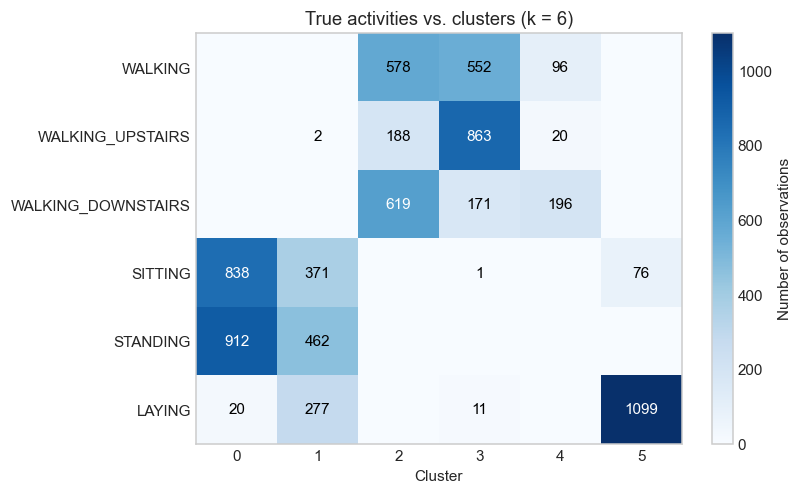

In [17]:
ct6 = pd.crosstab(y_named, labels_k[6]).reindex(order)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
im = ax.imshow(ct6, cmap="Blues", aspect="auto")

ax.set_xticks(range(ct6.shape[1]), ct6.columns)
ax.set_yticks(range(ct6.shape[0]), ct6.index)
ax.set_xlabel("Cluster")
ax.set_title("True activities vs. clusters (k = 6)")
ax.grid(False)

vmax = ct6.to_numpy().max()
for i in range(ct6.shape[0]):
    for j in range(ct6.shape[1]):
        v = int(ct6.iat[i, j])
        if v:
            ax.text(j, i, v, ha="center", va="center",
                    color="white" if v > 0.55 * vmax else "black")

fig.colorbar(im, ax=ax, label="Number of observations")
fig.tight_layout()
plt.show()

## 6. Conclusions

**Without labels, K-means found two groups rather than six — and found them almost perfectly.** With k = 2, the
walking activities land in one cluster and the static ones (sitting, standing, lying) in the other, with only
**17 errors in 7,352** observations. Moving versus not moving is the dominant structure in the data.

**With k = 6, each group splits into three, with very different success:**

* **Lying down is recognised well.** 1,099 of 1,407 lying observations form their own cluster, which contains only
  76 others. When a person lies down the phone turns over, so gravity acts on a different sensor axis — a strong,
  unambiguous signal.
* **Sitting and standing cannot be told apart.** Both are spread over the same two clusters (838 and 912, 371 and
  462). A phone on the waist hangs at roughly the same angle in both poses and is motionless in both.
* **The three walking types overlap.** Most upstairs observations (863 of 1,073) fall into one cluster and most
  downstairs observations (619 of 986) into another, but ordinary walking divides almost evenly between those same
  two clusters (578 and 552). Climbing stairs is walking with a slightly different step, so there is no clean boundary.

**Agreement with the true labels.** ARI is 0.414 for k = 6 against 0.329 for k = 2 (NMI 0.554 against 0.545). Six
clusters are closer to the real activities even though the elbow method and silhouette score both favoured two: the
statistically cleanest split is not always the most useful one for the question being asked.